# Long Short-Term Memory (LSTM) Networks

## What is an LSTM?
Long Short-Term Memory (LSTM) is an advanced architecture of **Recurrent Neural Networks (RNN)**. It was specifically designed to learn long-term dependencies in sequence data, overcoming the major limitations of traditional RNNs.

## Why use LSTMs? (The Problem it Solves)
When processing long sequences of data, standard RNNs suffer from the **Vanishing and Exploding Gradient Problem**. Because they repeatedly multiply the same weight matrices across many time steps during backpropagation, the gradients either shrink towards zero (the network "forgets" earlier inputs and stops learning) or grow infinitely large (the network becomes unstable). 

LSTMs solve this by introducing an internal mechanism called **gates** that can regulate the flow of information, deciding exactly what to keep, what to update, and what to throw away.

---

## Architecture & Mathematical Intuition

The core intuition behind LSTMs is the separation of memory into two distinct paths:
1. **Cell State ($C_t$)**: The long-term memory. It acts like a conveyer belt or highway running straight down the entire chain, with only minor linear interactions. It's very easy for information to flow along it unchanged.
2. **Hidden State ($h_t$)**: The short-term memory (and the actual output of the LSTM cell at time $t$).

LSTMs control the Cell State using three primary "gates." These gates use the **Sigmoid ($\sigma$)** activation function (outputs $0$ to $1$, where $0$ means "let nothing through" and $1$ means "let everything through") and the **Tanh** function (outputs $-1$ to $1$ to normalize values).

### 1. Forget Gate
Decides what information from the long-term memory should be thrown away or kept. It looks at the previous hidden state and current input.
$$f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$$

### 2. Input Gate
Decides what new information is going to be stored in the long-term memory. It has two parts:
* A sigmoid layer decides which values we will update: 
  $$i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$$
* A tanh layer creates a vector of new candidate values: 
  $$\tilde{C}_t = \tanh(W_c \cdot [h_{t-1}, x_t] + b_c)$$

### 3. Cell State Update
We then update the old cell state ($C_{t-1}$) into the new cell state ($C_t$) by multiplying the old state by the forget gate, and adding the new scaled candidate values.
$$C_t = f_t \cdot C_{t-1} + i_t \cdot \tilde{C}_t$$

### 4. Output Gate
Decides what the next hidden state (short-term memory) should be. The hidden state is a filtered version of our new cell state.
$$o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$$
$$h_t = o_t \cdot \tanh(C_t)$$

---

## Common Applications
Due to their ability to process sequences and remember past contexts, LSTMs are widely used in:
* **Time Series Forecasting:** Predicting stock prices, weather, or energy demand.
* **Natural Language Processing (NLP):** Text classification, sentiment analysis, and historically, machine translation (though mostly superseded by Transformers like GPT/BERT for large-scale tasks).
* **Speech Recognition:** Converting speech to text, as speech is inherently a sequence of audio signals over time.
* **Anomaly Detection:** Monitoring server logs, ECG data, or network traffic for unusual sequences of events.

---

In [23]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import torch_directml

In [24]:
NUM_DATA_POINTS = 1000
NUM_EPOCHS = 100
LEARNING_RATE = 0.01
# DEVICE = torch_directml.device(0)     torch_directml is not available as it doesn't support all the operations in recurrent layers
DEVICE = torch.device('cpu')

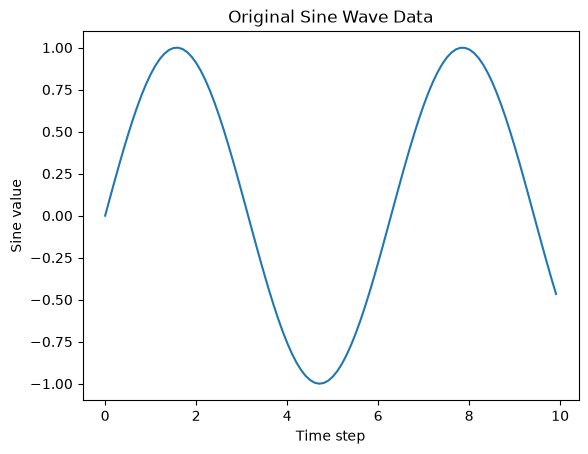

In [25]:
x_values = np.linspace(0, 100, NUM_DATA_POINTS)

# Calculate the sine of each x value to create our time series data
y_values = np.sin(x_values)

# Plot the first 100 points to visualize the generated sine wave
plt.plot(x_values[:100], y_values[:100])
plt.title("Original Sine Wave Data")
plt.xlabel("Time step")
plt.ylabel("Sine value")
plt.show()

# Data Preparation for LSTMs: The Sliding Window

Unlike standard feedforward neural networks that can take a flat list of numbers, LSTMs require data to be structured in sequences to understand chronology and time dependencies. 

To achieve this, we use a technique called the **Sliding Window**.

## The Sliding Window Concept

Imagine looking at a time series through a small window. You can only see $N$ consecutive data points at a time. You use those $N$ points to guess the very next point ($N+1$). Then, you slide the window one step into the future and repeat the process.

*   **Window (Input/X):** A sequence of historical data points (e.g., 20 time steps).
*   **Target (Label/Y):** The immediate next data point we want the model to predict.

By doing this, we transform an unsupervised continuous stream of data into a supervised learning problem (providing the model with a clear "question" and "answer").

## Tensor Conversion and The 3D Shape Rule

Once the data is split into windows using NumPy, it must be converted for PyTorch.

1.  **Tensor Casting:** We convert the NumPy arrays into `torch.tensor` and cast them as `torch.float32` (the standard precision for neural network weights). We also send them directly to our computing `DEVICE` (CPU or GPU).
2.  **The 3D Requirement:** PyTorch's `nn.LSTM` strictly expects inputs to be a 3-Dimensional tensor in the following format:
    *   **Dimension 1 (Batch Size):** How many sequence windows we have in total (e.g., 980).
    *   **Dimension 2 (Sequence Length):** How many time steps are in a single window (e.g., 20).
    *   **Dimension 3 (Num Features):** How many variables exist at a single time step (e.g., 1, because we only track the sine wave value).

Because our initial sliding window output is only 2D (`[980, 20]`), we use `unsqueeze(-1)` to artificially append the required third dimension at the very end.

In [26]:
# Function to create sequences (features) and corresponding labels (targets)
def create_sequences(data, sequence_length):
    inputs = []
    targets = []
    
    # Iterate through the data to create sliding windows
    for i in range(len(data) - sequence_length):
        # Extract a window of 'sequence_length' points
        window = data[i:(i + sequence_length)]
        # The target is the immediate next point after the window
        target = data[i + sequence_length]
        
        inputs.append(window)
        targets.append(target)
        
    return np.array(inputs), np.array(targets)

# Set the sequence length (how many past steps the model looks at)
seq_length = 20

# Generate the formatted inputs (X) and targets (y)
X_data, y_target = create_sequences(y_values, seq_length)

# Convert numpy arrays to PyTorch tensors and cast to 32-bit floating point
X_tensor = torch.tensor(X_data, dtype=torch.float32, device=DEVICE)
y_tensor = torch.tensor(y_target, dtype=torch.float32, device=DEVICE)

# Reshape tensors to match PyTorch LSTM expectations: [batch_size, sequence_length, num_features]
# unsqueeze(-1) adds a new dimension at the last position (index -1)
X_tensor = X_tensor.unsqueeze(-1)
y_tensor = y_tensor.unsqueeze(-1)

print(f"Shape of input tensor (X_tensor): {X_tensor.shape}") 
# Expected: torch.Size([980, 20, 1])
print(f"Shape of target tensor (y_tensor): {y_tensor.shape}") 
# Expected: torch.Size([980, 1])

Shape of input tensor (X_tensor): torch.Size([980, 20, 1])
Shape of target tensor (y_tensor): torch.Size([980, 1])


# Building the LSTM Model Architecture

In PyTorch, neural networks are constructed using Object-Oriented Programming. We create a custom class that inherits from `nn.Module`, allowing us to stack different neural network layers like building blocks.

## 1. The Initialization (`__init__`)

The `__init__` method is the blueprint of our network. It defines *what* layers exist, but not how data flows through them yet.

* **`nn.LSTM` Layer:** The core of our model.
  * `input_size=1`: Our sequence only has one feature per time step (the sine wave amplitude).
  * `hidden_size=50`: The number of neurons inside the LSTM cell (its memory capacity). A larger number can capture more complex patterns but takes longer to train.
  * `batch_first=True`: A crucial setting. It tells PyTorch that the input tensors will have the batch size as the very first dimension `[batch, sequence, feature]` instead of the default `[sequence, batch, feature]`.

* **`nn.Linear` Layer (Fully Connected):** 
  * The LSTM layer outputs 50 hidden features. However, we only want to predict a single numeric value (the next point on the wave). 
  * This layer acts as a translator, squeezing the `hidden_size` (50) down to the `output_size` (1).

## 2. The Forward Pass (`forward`)

The `forward` method defines the actual journey of the data through our established layers. 

1. **Processing the Sequence:** We pass the input `x` into `self.lstm(x)`. It returns two things:
   * `lstm_out`: The hidden states for **every single time step** in the sequence.
   * `_` (tuple of hn, cn): The final hidden and cell states. We use an underscore to ignore them because `lstm_out` already contains what we need.

2. **Extracting the Final State:** 
   * **`lstm_out[:, -1, :]`**: This is the most critical line for sequence forecasting. 
   * We don't want to make predictions based on the middle of the window; we only want to predict what happens *after* the entire window has been processed. 
   * This slicing syntax means: grab all batches (`:`), pick only the very last time step (`-1`), and keep all 50 hidden features (`:`).

3. **Making the Prediction:** We pass that final time step's state through our `self.linear` layer to get our single output number.

In [27]:
class SineLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, output_size=1):
        super(SineLSTM, self).__init__()
        
        # Store the hidden size for later reference if needed
        self.hidden_size = hidden_size
        
        # Define the LSTM layer
        # batch_first=True tells the model to expect input tensors of shape (batch, seq, feature)
        self.lstm = nn.LSTM(input_size=input_size, 
                            hidden_size=hidden_size, 
                            batch_first=True)
        
        # Define the fully connected (linear) layer to map LSTM output to our single numeric prediction
        self.linear = nn.Linear(in_features=hidden_size, out_features=output_size)

    def forward(self, x):
        # Pass input sequence through the LSTM layer
        # lstm_out contains all hidden states across all time steps
        # We ignore the returned final hidden state and cell state tuples (_)
        lstm_out, _ = self.lstm(x)
        
        # Extract the hidden state from the very last time step of the sequence
        # Syntax means: [all_batches, last_time_step, all_hidden_features]
        last_time_step_out = lstm_out[:, -1, :]
        
        # Map the final hidden state to a single output value
        prediction = self.linear(last_time_step_out)
        
        return prediction

# Instantiate the model
model = SineLSTM().to(DEVICE)
print(model)

SineLSTM(
  (lstm): LSTM(1, 50, batch_first=True)
  (linear): Linear(in_features=50, out_features=1, bias=True)
)


In [28]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [29]:
for epoch in range(NUM_EPOCHS):
    predictions = model(X_tensor)
    loss = criterion(predictions, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 20 == 0:
        print(f'Epoch [{epoch+1}/{NUM_EPOCHS}], Loss: {loss.item():.6f}')

Epoch [20/100], Loss: 0.001039
Epoch [40/100], Loss: 0.000602
Epoch [60/100], Loss: 0.000071
Epoch [80/100], Loss: 0.000032
Epoch [100/100], Loss: 0.000018


# Interpreting the LSTM Output

After training the model and running the evaluation, we generate a plot to visually compare the true data with our model's predictions.

## What Are We Looking At?

The graph displays the first 200 time steps of our dataset. 
* The **Solid Blue Line** represents the ground truth: the actual mathematical sine wave we generated at the very beginning.
* The **Dashed Red Line** represents the LSTM's predictions.

## How to Interpret the Results

### 1. The Perfect Overlap (Pattern Recognition)
The most obvious takeaway is that the red dashed line almost perfectly overlays the blue line. This visual alignment indicates that the training was highly successful. The loss (MSE) dropped to near zero, and the model has effectively "learned" the cyclical, non-linear pattern of a sine wave. 

### 2. One-Step-Ahead Prediction
It is crucial to understand *what* the model is actually doing here. The model did not draw this entire red wave from memory. Instead, it is performing **one-step-ahead forecasting**:
For every single point on that red line (e.g., time step 100), the model looked at the previous 20 points (time steps 80 through 99) and predicted just that single next value. The graph is a collection of 200 individual, consecutive predictions.

### 3. The "Overfitting" Caveat (A Word of Caution)
While this result looks flawless, we must view it with a critical eye. In this script, we evaluated the model using the **exact same data** it was trained on. 

In real-world machine learning:
* Testing a model on its own training data is generally considered bad practice because a sufficiently complex model might just "memorize" the answers rather than learning the underlying logic.
* To prove that an LSTM is truly effective and can generalize, we must implement a **Train/Test Split**. We would train the model on the first 80% of the wave and then ask it to predict the remaining 20% that it has *never seen before*. 

However, for a foundational proof-of-concept to understand how tensor shapes and recurrent gates work, this perfect overlap is exactly the milestone we wanted to reach!

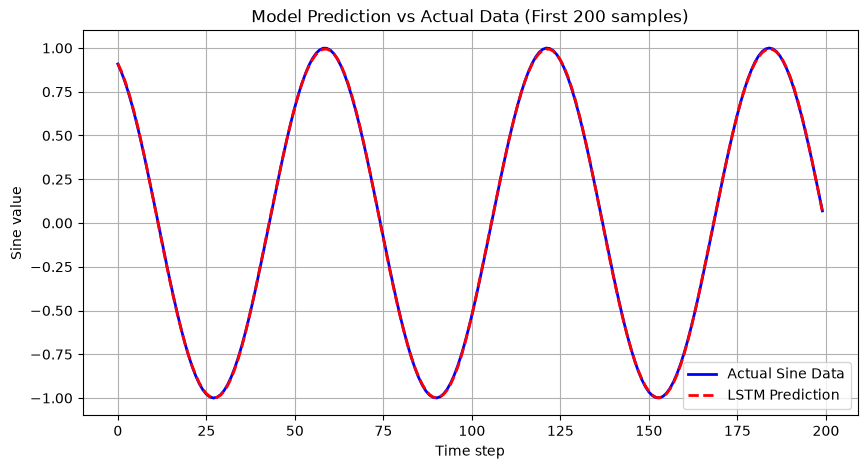

In [30]:
model.eval()

with torch.no_grad():
    predicted_tensor = model(X_tensor)
    
    predicted_numpy = predicted_tensor.cpu().numpy().squeeze()
    actual_numpy = y_tensor.cpu().numpy().squeeze()

plt.figure(figsize=(10, 5))
plt.plot(actual_numpy[:200], label='Actual Sine Data', color='blue', linewidth=2)
plt.plot(predicted_numpy[:200], label='LSTM Prediction', color='red', linestyle='--', linewidth=2)
plt.title("Model Prediction vs Actual Data (First 200 samples)")
plt.xlabel("Time step")
plt.ylabel("Sine value")
plt.legend()
plt.grid(True)
plt.show()

# Forecasting into the Unknown Future

Once an LSTM is trained, the ultimate goal is often to predict future data points that do not yet exist in our dataset. The provided code demonstrates two ways to achieve this, culminating in a visual forecast.

## 1. Interpreting the Text Output (One-Step Ahead)

```text
One-step ahead prediction (Step 1001): -0.5062
```
This single numeric output represents the model's immediate prediction for the very next time step. The model looked at the final 20 points of our known dataset (steps 981 to 1000) and calculated that the wave is currently on a downward trajectory, placing the next point at approximately `-0.5062`. 

## 2. Interpreting the Visual Output (Autoregression)

The graph provides a visual representation of **Autoregressive (Multi-Step) Forecasting**. 

### What the Graph Shows:
* **The Solid Blue Line (Left):** This represents the final 100 points of our actual, historical dataset (steps 900 to 1000). 
* **The Dashed Red Line (Right):** This represents 100 entirely new data points (steps 1000 to 1100) generated into the "unknown future."

### How to Interpret It:
1. **The Power of Autoregression:** The model generated the red line without seeing *any* real data beyond step 1000. It predicted step 1001, added that prediction to its own input window, and then used its *own prediction* to guess step 1002. It repeated this loop 100 times.
2. **Perfect Continuation:** Visually, the red dashed line connects seamlessly to the blue line and maintains the exact amplitude and frequency of the sine wave. This proves the LSTM has successfully internalized the underlying mathematical rules of the sequence.

### The Real-World Caveat (Error Compounding)
While this looks flawless, interpreting this output requires understanding the nature of our data. A sine wave is a perfect, noise-free mathematical construct. 

In real-world scenarios (like stock prices or weather forecasting):
* Every prediction contains a tiny margin of error.
* Because the model uses its own predictions to make future predictions, these tiny errors **compound rapidly**.
* If we applied this exact autoregressive loop to a real-world dataset, the red line would likely look accurate for the first few steps, but would quickly drift away from reality, eventually flattening out or spiraling out of control. 

This graph perfectly illustrates that LSTMs are excellent pattern learners, but long-term multi-step forecasting requires extremely stable underlying patterns to remain accurate.

One-step ahead prediction (Step 1001): -0.5062


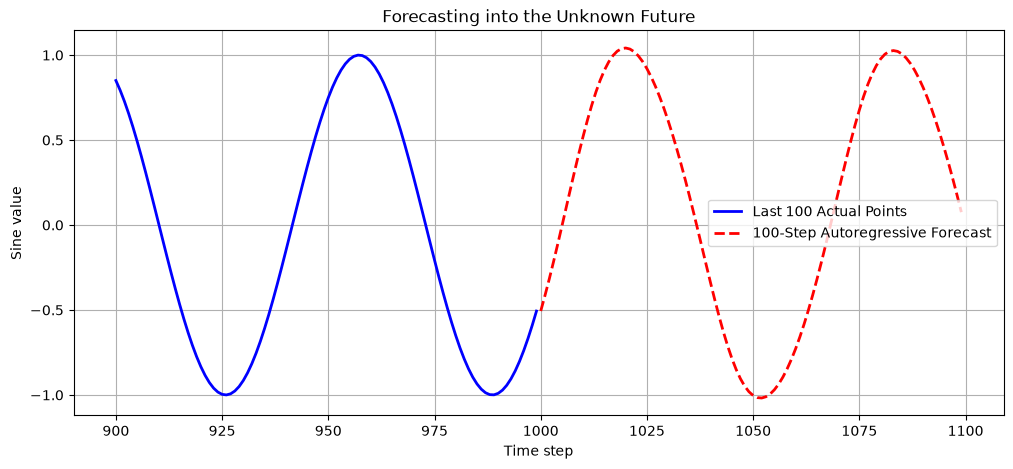

In [31]:
# 1. ONE-STEP AHEAD PREDICTION
model.eval()

# Get the very last window of our known data
# unsqueeze(0) adds the batch dimension back so shape is [1, 20, 1]
last_known_window = X_tensor[-1].unsqueeze(0)

with torch.no_grad():
    # Predict step 1001 based on steps 981-1000
    single_next_step = model(last_known_window)
    print(f"One-step ahead prediction (Step 1001): {single_next_step.item():.4f}")


# 2. AUTOREGRESSIVE (MULTI-STEP) FORECASTING
num_future_steps = 100
future_predictions = []

# Start with the same last known window
current_window = X_tensor[-1].unsqueeze(0)

with torch.no_grad():
    for i in range(num_future_steps):
        # Predict the immediate next value
        next_pred = model(current_window)
        
        # Store the predicted value
        future_predictions.append(next_pred.item())
        
        # Reshape the prediction to match window dimensions: [batch, seq_len, features] -> [1, 1, 1]
        next_pred_reshaped = next_pred.unsqueeze(1)
        
        # Update the window:
        # Keep everything from index 1 onwards (drop the oldest point), and concatenate the new prediction at the end
        current_window = torch.cat((current_window[:, 1:, :], next_pred_reshaped), dim=1)

# 3. VISUALIZATION
# Create an x-axis for the future points (from 1000 to 1100)
future_x_axis = np.arange(NUM_DATA_POINTS, NUM_DATA_POINTS + num_future_steps)

plt.figure(figsize=(12, 5))

# Plot the last 100 points of the actual data to see the connection
plt.plot(np.arange(900, 1000), y_values[900:1000], label='Last 100 Actual Points', color='blue', linewidth=2)

# Plot the 100 future steps generated purely by the model
plt.plot(future_x_axis, future_predictions, label='100-Step Autoregressive Forecast', color='red', linestyle='--', linewidth=2)

plt.title("Forecasting into the Unknown Future")
plt.xlabel("Time step")
plt.ylabel("Sine value")
plt.legend()
plt.grid(True)
plt.show()